# Deep Retention — Análisis financiero académico de retención

Este notebook integra el nuevo dataset, el MLP ya entrenado y el catálogo de
incentivos para construir un escenario financiero **simulado, reproducible y
auditable**. Los importes no representan datos contables reales ni beneficios
observados del banco.

El flujo conserva por separado:

- las 18 variables observadas del CSV;
- ocho variables financieras generadas mediante supuestos explícitos;
- las probabilidades ajustadas del MLP;
- las decisiones y métricas de GNE, que se usan para el análisis pero no se
  añaden al CSV financiero.


## 1. Introducción, objetivo y alcance

El objetivo es crear una aproximación académica de rentabilidad por cliente y
aplicar la regla:

[
GNE=(P_f 	imes E_i 	imes M_c)-C_i
]

donde (P_f) es la probabilidad de fuga, (E_i) la efectividad hipotética del
incentivo, (M_c) el margen neto anual simulado y (C_i) su costo anual. La
simulación no utiliza `Exited` ni `Complain` y no reentrena el MLP.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    candidate
    for candidate in [Path.cwd(), *Path.cwd().parents]
    if (candidate / "data" / "Customer-Churn-Records.csv").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.financial import (
    calcular_umbrales_comerciales,
    evaluar_cartera,
    resumir_cartera,
    validar_catalogo,
)
from src.prediction import PredictorFuga

DATA_PATH = PROJECT_ROOT / "data" / "Customer-Churn-Records.csv"
CATALOG_PATH = PROJECT_ROOT / "data" / "incentivos.csv"
OUTPUT_PATH = (
    PROJECT_ROOT / "data" / "processed" / "clientes_financieros_simulados.csv"
)

df_original = pd.read_csv(DATA_PATH)
original_columns = df_original.columns.tolist()
df_financial = df_original.copy()

print("Dataset: {:,} filas × {} columnas".format(*df_original.shape))
display(df_original.head(3))


Dataset: 10,000 filas × 18 columnas


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377


## 2. Carga y diagnóstico de la información financiera faltante

El CSV contiene saldos, productos, actividad y antigüedad, pero no registra
transacciones, comisiones, costos operativos, margen financiero ni margen neto
del banco. `Balance` se conserva en su unidad original y
`EstimatedSalary` describe al cliente; ninguna se transforma directamente en
ingreso bancario.


In [2]:
FINANCIAL_COLUMNS = [
    "MonthlyTransactions_Sim",
    "MonthlyTransactionVolume_USD_Sim",
    "AvgTransactionFee_USD_Sim",
    "AnnualCommissionIncome_USD_Sim",
    "AnnualFinancialMargin_USD_Sim",
    "AnnualOperatingCosts_USD_Sim",
    "AnnualNetMargin_USD_Sim",
    "ProfitabilitySegment_Sim",
]

diagnosis = pd.DataFrame(
    {
        "información requerida": [
            "Actividad transaccional",
            "Volumen transaccional",
            "Comisión por transacción",
            "Contribución financiera",
            "Costos operativos",
            "Margen neto",
        ],
        "disponible directamente": [False] * 6,
        "tratamiento": [
            "Regla determinista con productos, actividad y antigüedad",
            "Transacciones × importe medio hipotético",
            "Tarifa hipotética según cantidad de productos",
            "Segmentos de percentiles de saldo y productos",
            "Costo fijo más componentes por producto y actividad",
            "Ingresos simulados menos costos simulados",
        ],
    }
)
display(diagnosis)
print("Columnas financieras presentes antes de simular:", [
    column for column in FINANCIAL_COLUMNS if column in df_original
])


,información requerida,disponible directamente,tratamiento
0,Actividad transaccional,False,"Regla determinista con productos, actividad y ..."
1,Volumen transaccional,False,Transacciones × importe medio hipotético
2,Comisión por transacción,False,Tarifa hipotética según cantidad de productos
3,Contribución financiera,False,Segmentos de percentiles de saldo y productos
4,Costos operativos,False,Costo fijo más componentes por producto y acti...
5,Margen neto,False,Ingresos simulados menos costos simulados


Columnas financieras presentes antes de simular: []


## 3. Supuestos y parámetros financieros

Todos los coeficientes se centralizan en `FINANCIAL_PARAMETERS`. Se eligieron
magnitudes anuales sencillas para ilustrar el método, no para alcanzar una
cantidad predeterminada de clientes rentables o campañas aprobadas.

- La actividad aumenta con productos, condición activa y antigüedad.
- El volumen usa un importe medio hipotético; no convierte el saldo en ventas.
- La comisión media aumenta moderadamente con la complejidad de productos.
- La contribución financiera usa segmentos de saldo, no un porcentaje del saldo.
- Los costos incorporan una base anual, productos y servicio transaccional.


In [3]:
FINANCIAL_PARAMETERS = {
    "transactions_base": 6,
    "transactions_per_product": 4,
    "transactions_active_bonus": 8,
    "tenure_months_per_step": 2,
    "average_ticket_base_usd": 65.0,
    "average_ticket_per_product_usd": 15.0,
    "average_ticket_active_bonus_usd": 20.0,
    "fee_base_usd": 0.45,
    "fee_per_product_usd": 0.10,
    "balance_segment_margin_usd": {
        0: 0.0,
        1: 120.0,
        2: 240.0,
        3: 420.0,
        4: 700.0,
    },
    "financial_margin_per_product_usd": 70.0,
    "financial_margin_active_bonus_usd": 60.0,
    "operating_fixed_cost_usd": 90.0,
    "operating_cost_per_product_usd": 25.0,
    "operating_cost_per_monthly_transaction_usd": 0.80,
}

positive_balances = df_original.loc[df_original["Balance"].gt(0), "Balance"]
BALANCE_QUARTILES = positive_balances.quantile([0.25, 0.50, 0.75]).to_dict()

parameter_table = pd.DataFrame(
    [
        {"parámetro": key, "valor": value}
        for key, value in FINANCIAL_PARAMETERS.items()
        if key != "balance_segment_margin_usd"
    ]
)
display(parameter_table)
display(
    pd.Series(
        FINANCIAL_PARAMETERS["balance_segment_margin_usd"],
        name="margen_anual_hipotético_usd",
    )
    .rename_axis("segmento_saldo")
    .to_frame()
)
display(
    pd.Series(BALANCE_QUARTILES, name="Balance_unidad_original")
    .rename_axis("percentil")
    .to_frame()
)


,parámetro,valor
0,transactions_base,6.00
1,transactions_per_product,4.00
2,transactions_active_bonus,8.00
3,tenure_months_per_step,2.00
4,average_ticket_base_usd,65.00
5,average_ticket_per_product_usd,15.00
6,average_ticket_active_bonus_usd,20.00
7,fee_base_usd,0.45
8,fee_per_product_usd,0.10
9,financial_margin_per_product_usd,70.00


,margen_anual_hipotético_usd
segmento_saldo,
0,0.0
1,120.0
2,240.0
3,420.0
4,700.0


,Balance_unidad_original
percentil,
0.25,100181.975
0.50,119839.690
0.75,139512.290


## 4. Generación de las ocho variables financieras simuladas

Las reglas siguientes son deterministas. El segmento 0 corresponde a saldo
cero; los segmentos 1 a 4 utilizan los cuartiles calculados únicamente entre
clientes con saldo positivo.


In [4]:
def generate_financial_variables(clients, parameters, balance_quartiles):
    """Genera exactamente las ocho variables financieras académicas."""

    transactions = (
        parameters["transactions_base"]
        + parameters["transactions_per_product"] * clients["NumOfProducts"]
        + parameters["transactions_active_bonus"] * clients["IsActiveMember"]
        + np.floor(
            clients["Tenure"] / parameters["tenure_months_per_step"]
        ).astype(int)
    ).astype(int)

    average_ticket = (
        parameters["average_ticket_base_usd"]
        + parameters["average_ticket_per_product_usd"]
        * clients["NumOfProducts"]
        + parameters["average_ticket_active_bonus_usd"]
        * clients["IsActiveMember"]
    )
    monthly_volume = transactions * average_ticket

    average_fee = (
        parameters["fee_base_usd"]
        + parameters["fee_per_product_usd"] * clients["NumOfProducts"]
    )
    annual_commission = transactions * average_fee * 12

    balance = clients["Balance"]
    q25 = balance_quartiles[0.25]
    q50 = balance_quartiles[0.50]
    q75 = balance_quartiles[0.75]
    balance_segment = np.select(
        [
            balance.eq(0),
            balance.le(q25),
            balance.le(q50),
            balance.le(q75),
        ],
        [0, 1, 2, 3],
        default=4,
    ).astype(int)
    segment_margin = pd.Series(balance_segment, index=clients.index).map(
        parameters["balance_segment_margin_usd"]
    )
    annual_financial_margin = (
        segment_margin
        + parameters["financial_margin_per_product_usd"]
        * clients["NumOfProducts"]
        + parameters["financial_margin_active_bonus_usd"]
        * clients["IsActiveMember"]
    )

    annual_operating_costs = (
        parameters["operating_fixed_cost_usd"]
        + parameters["operating_cost_per_product_usd"]
        * clients["NumOfProducts"]
        + parameters["operating_cost_per_monthly_transaction_usd"]
        * transactions
        * 12
    )
    annual_net_margin = (
        annual_commission
        + annual_financial_margin
        - annual_operating_costs
    )

    return pd.DataFrame(
        {
            "MonthlyTransactions_Sim": transactions,
            "MonthlyTransactionVolume_USD_Sim": monthly_volume,
            "AvgTransactionFee_USD_Sim": average_fee,
            "AnnualCommissionIncome_USD_Sim": annual_commission,
            "AnnualFinancialMargin_USD_Sim": annual_financial_margin,
            "AnnualOperatingCosts_USD_Sim": annual_operating_costs,
            "AnnualNetMargin_USD_Sim": annual_net_margin,
            "ProfitabilitySegment_Sim": np.where(
                annual_net_margin.gt(0), "Rentable", "Deficitario"
            ),
        },
        index=clients.index,
    )


simulated_financials = generate_financial_variables(
    df_original, FINANCIAL_PARAMETERS, BALANCE_QUARTILES
)
df_financial[FINANCIAL_COLUMNS] = simulated_financials[FINANCIAL_COLUMNS]

print("Columnas simuladas:", FINANCIAL_COLUMNS)
display(df_financial[["CustomerId", *FINANCIAL_COLUMNS]].head())


Columnas simuladas: ['MonthlyTransactions_Sim', 'MonthlyTransactionVolume_USD_Sim', 'AvgTransactionFee_USD_Sim', 'AnnualCommissionIncome_USD_Sim', 'AnnualFinancialMargin_USD_Sim', 'AnnualOperatingCosts_USD_Sim', 'AnnualNetMargin_USD_Sim', 'ProfitabilitySegment_Sim']


,CustomerId,MonthlyTransactions_Sim,MonthlyTransactionVolume_USD_Sim,AvgTransactionFee_USD_Sim,AnnualCommissionIncome_USD_Sim,AnnualFinancialMargin_USD_Sim,AnnualOperatingCosts_USD_Sim,AnnualNetMargin_USD_Sim,ProfitabilitySegment_Sim
0,15634602,19,1900.0,0.55,125.4,130.0,297.4,-42.0,Deficitario
1,15647311,18,1800.0,0.55,118.8,250.0,287.8,81.0,Rentable
2,15619304,22,2420.0,0.75,198.0,910.0,376.2,731.8,Rentable
3,15701354,14,1330.0,0.65,109.2,140.0,274.4,-25.2,Deficitario
4,15737888,19,1900.0,0.55,125.4,550.0,297.4,378.0,Rentable


Las identidades utilizadas son:

[
IngresosComisiones =
TransaccionesMensuales 	imes ComisiónPromedio 	imes 12
]

[
MargenNeto =
IngresosComisiones + ContribuciónFinanciera - CostosOperativos
]

El volumen mensual está expresado en USD simulados. El saldo continúa en su
unidad original y solo determina un segmento relativo de contribución.


## 5. Cálculo y análisis de rentabilidad por cliente


In [5]:
monetary_columns = [
    "MonthlyTransactionVolume_USD_Sim",
    "AvgTransactionFee_USD_Sim",
    "AnnualCommissionIncome_USD_Sim",
    "AnnualFinancialMargin_USD_Sim",
    "AnnualOperatingCosts_USD_Sim",
    "AnnualNetMargin_USD_Sim",
]
display(df_financial[monetary_columns].describe().T)

profitability_summary = (
    df_financial["ProfitabilitySegment_Sim"]
    .value_counts()
    .rename_axis("segmento")
    .to_frame("clientes")
)
profitability_summary["porcentaje"] = (
    profitability_summary["clientes"] / len(df_financial) * 100
)
display(profitability_summary)

commercial_segments = (
    df_financial.groupby(
        ["NumOfProducts", "IsActiveMember"], observed=False
    )
    .agg(
        clientes=("CustomerId", "size"),
        margen_medio_usd=("AnnualNetMargin_USD_Sim", "mean"),
        margen_mediano_usd=("AnnualNetMargin_USD_Sim", "median"),
        clientes_rentables=(
            "ProfitabilitySegment_Sim",
            lambda values: int(values.eq("Rentable").sum()),
        ),
    )
    .reset_index()
)
commercial_segments["rentables_pct"] = (
    commercial_segments["clientes_rentables"]
    / commercial_segments["clientes"]
    * 100
)
display(commercial_segments)


,count,mean,std,min,25%,50%,75%,max
MonthlyTransactionVolume_USD_Sim,10000.0,1877.77850,720.951267,800.00,1200.00,1805.00,2530.00,5075.00
AvgTransactionFee_USD_Sim,10000.0,0.60302,0.058165,0.55,0.55,0.55,0.65,0.85
AnnualCommissionIncome_USD_Sim,10000.0,135.49608,43.843876,66.00,99.00,132.00,171.60,357.00
AnnualFinancialMargin_USD_Sim,10000.0,374.18600,244.418722,70.00,190.00,310.00,550.00,1040.00
AnnualOperatingCosts_USD_Sim,10000.0,305.80316,55.177176,211.00,259.00,303.20,351.20,526.00
AnnualNetMargin_USD_Sim,10000.0,203.87892,244.426720,-90.00,15.00,135.00,372.00,870.40


,clientes,porcentaje
segmento,,
Rentable,7880,78.8
Deficitario,2120,21.2


,NumOfProducts,IsActiveMember,clientes,margen_medio_usd,margen_mediano_usd,clientes_rentables,rentables_pct
0,1,0,2521,222.634669,159.0,2048,81.237604
1,1,1,2563,258.865392,195.0,2131,83.144752
2,2,0,2144,130.336754,-25.2,929,43.330224
3,2,1,2446,176.424448,20.4,2446,100.000000
4,3,0,153,277.484967,271.8,153,100.000000
5,3,1,113,309.446018,207.6,113,100.000000
6,4,0,31,382.483871,344.4,31,100.000000
7,4,1,29,475.841379,411.0,29,100.000000


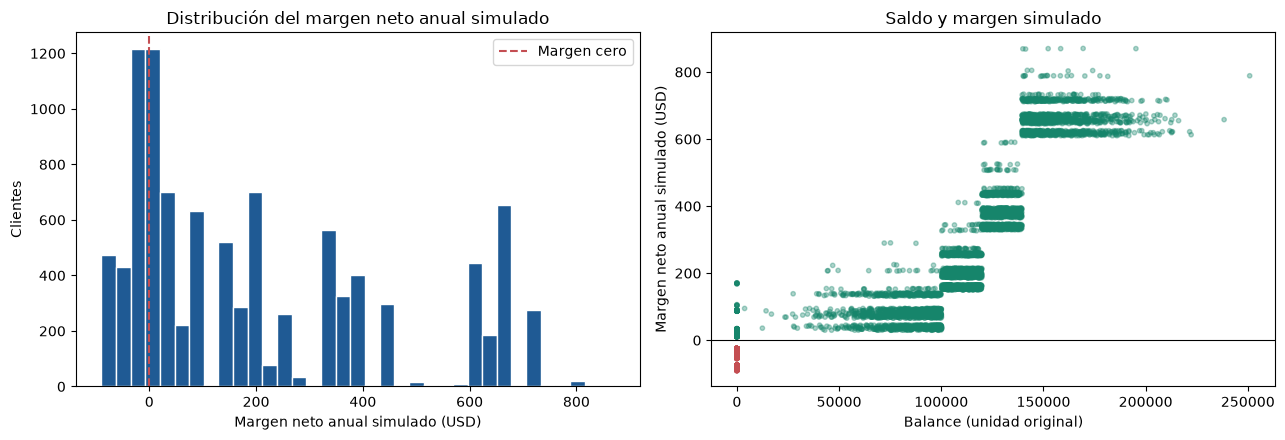

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(
    df_financial["AnnualNetMargin_USD_Sim"],
    bins=35,
    color="#1F5A94",
    edgecolor="white",
)
axes[0].axvline(0, color="#C44E52", linestyle="--", label="Margen cero")
axes[0].set(
    title="Distribución del margen neto anual simulado",
    xlabel="Margen neto anual simulado (USD)",
    ylabel="Clientes",
)
axes[0].legend()

colors = np.where(
    df_financial["ProfitabilitySegment_Sim"].eq("Rentable"),
    "#16856B",
    "#C44E52",
)
axes[1].scatter(
    df_financial["Balance"],
    df_financial["AnnualNetMargin_USD_Sim"],
    c=colors,
    s=10,
    alpha=0.35,
)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(
    title="Saldo y margen simulado",
    xlabel="Balance (unidad original)",
    ylabel="Margen neto anual simulado (USD)",
)

plt.tight_layout()
plt.show()


Un saldo elevado no garantiza por sí solo una mayor rentabilidad: el margen
simulado también depende de productos, actividad, comisiones y costos de
servicio. El gráfico muestra la asociación creada por los segmentos de saldo,
pero conserva dispersión por los demás componentes. Esta relación pertenece al
escenario académico, no a evidencia causal observada.


## 6. Integración de probabilidades del MLP


In [7]:
source_customer_ids = df_financial["CustomerId"].to_numpy(copy=True)
predictor = PredictorFuga()
probabilities = predictor.predecir_lote(df_financial, batch_size=256)

probability_results = pd.DataFrame(
    {
        "CustomerId": source_customer_ids,
        "probabilidad_fuga": probabilities,
    }
)
ids_remain_aligned = np.array_equal(
    probability_results["CustomerId"].to_numpy(),
    df_financial["CustomerId"].to_numpy(),
)
print("Probabilidades calculadas:", len(probabilities))
print(
    "Rango: {:.6f} a {:.6f}".format(
        float(probabilities.min()), float(probabilities.max())
    )
)
print("Correspondencia CustomerId–probabilidad:", ids_remain_aligned)
display(probability_results.head())


Probabilidades calculadas: 10000
Rango: 0.001482 a 0.999994
Correspondencia CustomerId–probabilidad: True


,CustomerId,probabilidad_fuga
0,15634602,0.221938
1,15647311,0.161567
2,15619304,0.992846
3,15701354,0.040575
4,15737888,0.062163


La probabilidad es un resultado separado de la simulación económica. El
predictor utiliza únicamente sus nueve características entrenadas y aplica la
corrección guardada; `Exited` y `Complain` no intervienen en inferencia ni
en la generación financiera.


## 7. Evaluación de incentivos y cálculo de GNE


In [8]:
catalog = validar_catalogo(pd.read_csv(CATALOG_PATH))
thresholds = calcular_umbrales_comerciales(df_financial, catalog)

display(catalog)
threshold_rows = [
    {
        "regla": rule,
        "percentil": percentile,
        "umbral": value,
    }
    for rule, values in thresholds.items()
    for percentile, value in values.items()
]
display(pd.DataFrame(threshold_rows))


,costo_anual_usd,efectividad,incentivo_id,margen_minimo_usd,nombre,percentil_balance_minimo,percentil_comision_minimo,percentil_transacciones_minimo,percentil_volumen_minimo,perfil_requerido
0,20,0.20,1,0,Bonificación transaccional,0.00,0.0,0.5,0.00,Transaccional
1,50,0.40,2,150,Exoneración de comisiones,0.00,0.5,0.0,0.00,Generador de comisiones
2,100,0.55,3,400,Tasa preferencial,0.75,0.0,0.0,0.50,Preferencial
3,200,0.75,4,800,Gestor personalizado,0.90,0.0,0.0,0.75,Patrimonial


,regla,percentil,umbral
0,percentil_transacciones_minimo,0.50,18.000
1,percentil_comision_minimo,0.50,132.000
2,percentil_balance_minimo,0.75,127644.240
3,percentil_balance_minimo,0.90,149244.792
4,percentil_volumen_minimo,0.50,1805.000
5,percentil_volumen_minimo,0.75,2530.000


In [9]:
portfolio_results = evaluar_cartera(
    df_financial,
    probabilities,
    catalog,
    thresholds,
)
portfolio_summary = resumir_cartera(portfolio_results)

alternatives = pd.DataFrame(
    [
        alternative
        for client_alternatives in portfolio_results["alternativas"]
        for alternative in client_alternatives
    ]
)
catalog_diagnostic = (
    alternatives.groupby(
        ["incentivo_id", "incentivo"], as_index=False
    )
    .agg(
        evaluaciones=("incentivo_id", "size"),
        elegibles_comerciales=("elegible_comercial", "sum"),
        elegibles_totales=("elegible", "sum"),
        gne_positiva=("gne_positiva", "sum"),
    )
)
recommended_counts = (
    portfolio_results.loc[
        portfolio_results["decision"].eq("Retener"), "incentivo"
    ]
    .value_counts()
    .rename("recomendados")
)
catalog_diagnostic = catalog_diagnostic.merge(
    recommended_counts,
    left_on="incentivo",
    right_index=True,
    how="left",
)
catalog_diagnostic["recomendados"] = (
    catalog_diagnostic["recomendados"].fillna(0).astype(int)
)
display(catalog_diagnostic)


,incentivo_id,incentivo,evaluaciones,elegibles_comerciales,elegibles_totales,gne_positiva,recomendados
0,1,Bonificación transaccional,7880,5146,5146,1626,335
1,2,Exoneración de comisiones,7880,4548,2344,1272,350
2,3,Tasa preferencial,7880,1186,939,812,102
3,4,Gestor personalizado,7880,188,6,435,6


## 8. Resultados financieros simulados de la cartera


,resultado
Clientes evaluados,10000.000000
Clientes rentables,7880.000000
Clientes deficitarios,2120.000000
Retener,793.000000
No intervención,7087.000000
Salida permitida,2120.000000
Inversión proyectada USD,35600.000000
GNE total simulada USD,42180.781401
ROI proyectado (%),118.485341


,clientes
incentivo,
Exoneración de comisiones,350
Bonificación transaccional,335
Tasa preferencial,102
Gestor personalizado,6


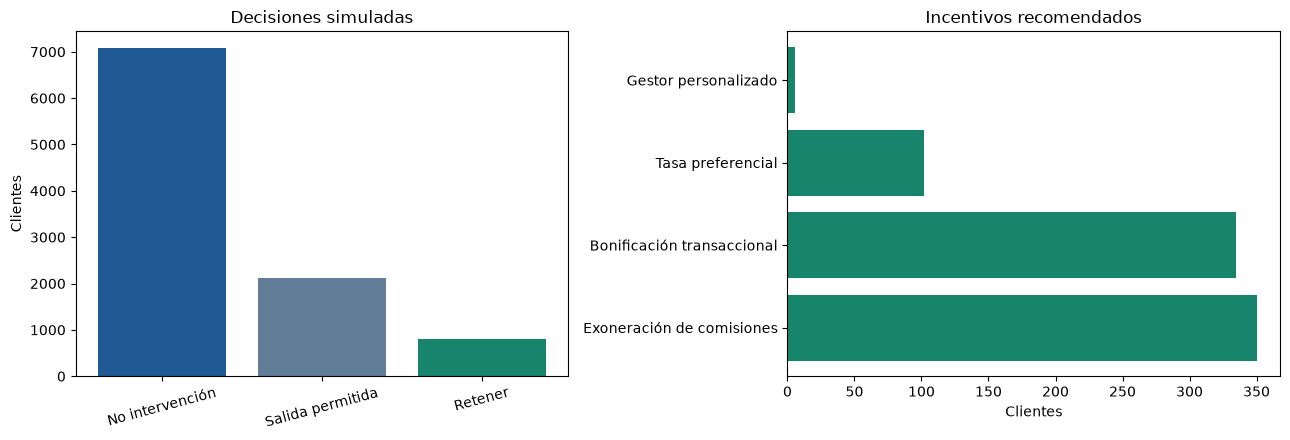

In [10]:
profitable_count = int(
    df_financial["AnnualNetMargin_USD_Sim"].gt(0).sum()
)
unprofitable_count = len(df_financial) - profitable_count

portfolio_kpis = pd.Series(
    {
        "Clientes evaluados": portfolio_summary["clientes_analizados"],
        "Clientes rentables": profitable_count,
        "Clientes deficitarios": unprofitable_count,
        "Retener": portfolio_summary["clientes_retener"],
        "No intervención": portfolio_summary[
            "clientes_no_intervencion"
        ],
        "Salida permitida": portfolio_summary[
            "clientes_salida_permitida"
        ],
        "Inversión proyectada USD": portfolio_summary[
            "inversion_total_usd"
        ],
        "GNE total simulada USD": portfolio_summary["gne_total_usd"],
        "ROI proyectado (%)": portfolio_summary[
            "roi_proyectado_pct"
        ],
    },
    name="resultado",
)
display(portfolio_kpis.to_frame())

incentive_distribution = (
    portfolio_results.loc[
        portfolio_results["decision"].eq("Retener"), "incentivo"
    ]
    .value_counts()
    .rename_axis("incentivo")
    .to_frame("clientes")
)
display(incentive_distribution)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
decision_counts = portfolio_results["decision"].value_counts()
axes[0].bar(
    decision_counts.index,
    decision_counts.values,
    color=["#1F5A94", "#627D98", "#16856B"],
)
axes[0].set(title="Decisiones simuladas", ylabel="Clientes")
axes[0].tick_params(axis="x", rotation=15)

axes[1].barh(
    incentive_distribution.index,
    incentive_distribution["clientes"],
    color="#16856B",
)
axes[1].set(
    title="Incentivos recomendados",
    xlabel="Clientes",
)
plt.tight_layout()
plt.show()


La inversión, la GNE y el ROI anteriores son proyecciones del escenario
simulado. No son ingresos realizados ni demuestran que las efectividades del
catálogo sean causales. El umbral 0,5 no participa en la selección: el motor
elige únicamente alternativas elegibles con GNE estrictamente positiva.


## 9. Validaciones, exportación y conclusiones


In [11]:
repeated_financials = generate_financial_variables(
    df_original, FINANCIAL_PARAMETERS, BALANCE_QUARTILES
)
pd.testing.assert_frame_equal(
    simulated_financials,
    repeated_financials,
    check_exact=True,
)
pd.testing.assert_frame_equal(
    df_financial[original_columns],
    df_original,
    check_dtype=True,
)

numeric_simulated_columns = [
    column
    for column in FINANCIAL_COLUMNS
    if column != "ProfitabilitySegment_Sim"
]
finite_values = bool(
    np.isfinite(
        df_financial[numeric_simulated_columns].to_numpy(dtype=float)
    ).all()
)
nonnegative_activity_and_costs = bool(
    df_financial[
        [
            "MonthlyTransactions_Sim",
            "MonthlyTransactionVolume_USD_Sim",
            "AvgTransactionFee_USD_Sim",
            "AnnualCommissionIncome_USD_Sim",
            "AnnualFinancialMargin_USD_Sim",
            "AnnualOperatingCosts_USD_Sim",
        ]
    ]
    .ge(0)
    .all()
    .all()
)
margin_identity = bool(
    np.allclose(
        df_financial["AnnualNetMargin_USD_Sim"],
        df_financial["AnnualCommissionIncome_USD_Sim"]
        + df_financial["AnnualFinancialMargin_USD_Sim"]
        - df_financial["AnnualOperatingCosts_USD_Sim"],
        rtol=0,
        atol=1e-10,
    )
)
retained = portfolio_results["decision"].eq("Retener")
financial_validation = pd.Series(
    {
        "10.000 clientes conservados": len(df_financial) == 10_000,
        "CustomerId únicos": df_financial["CustomerId"].is_unique,
        "18 columnas originales sin cambios": (
            df_financial[original_columns].equals(df_original)
        ),
        "ocho columnas simuladas exactas": (
            df_financial.columns.tolist()
            == original_columns + FINANCIAL_COLUMNS
        ),
        "valores numéricos finitos": finite_values,
        "actividad, ingresos y costos no negativos": (
            nonnegative_activity_and_costs
        ),
        "identidad del margen neto": margin_identity,
        "probabilidades entre 0 y 1": bool(
            np.isfinite(probabilities).all()
            and ((probabilities >= 0) & (probabilities <= 1)).all()
        ),
        "CustomerId y probabilidad alineados": ids_remain_aligned,
        "ningún margen no positivo recibe incentivo": bool(
            not (
                retained
                & portfolio_results["margen_anual_usd"].le(0)
            ).any()
        ),
        "retenciones elegibles con GNE positiva": bool(
            portfolio_results.loc[retained, "elegible"].all()
            and portfolio_results.loc[retained, "gne"].gt(0).all()
        ),
        "escenario reproducible": simulated_financials.equals(
            repeated_financials
        ),
    },
    name="resultado",
)
display(financial_validation.to_frame())
if not financial_validation.all():
    raise ValueError("Alguna validación financiera no fue superada.")

if not OUTPUT_PATH.parent.is_dir():
    raise FileNotFoundError(
        "No existe data/processed; ejecute primero el preprocesamiento."
    )
df_financial.to_csv(OUTPUT_PATH, index=False)
exported = pd.read_csv(OUTPUT_PATH)

export_validation = pd.Series(
    {
        "filas exportadas": len(exported) == 10_000,
        "columnas exportadas": exported.shape[1] == 26,
        "esquema exacto": exported.columns.tolist()
        == original_columns + FINANCIAL_COLUMNS,
        "CustomerId conservados": np.array_equal(
            exported["CustomerId"].to_numpy(),
            df_original["CustomerId"].to_numpy(),
        ),
    },
    name="resultado",
)
display(export_validation.to_frame())
if not export_validation.all():
    raise ValueError("El CSV exportado no coincide con el contrato esperado.")
print(
    "Exportación completada: "
    "data/processed/clientes_financieros_simulados.csv"
)


,resultado
10.000 clientes conservados,True
CustomerId únicos,True
18 columnas originales sin cambios,True
ocho columnas simuladas exactas,True
valores numéricos finitos,True
"actividad, ingresos y costos no negativos",True
identidad del margen neto,True
probabilidades entre 0 y 1,True
CustomerId y probabilidad alineados,True
ningún margen no positivo recibe incentivo,True


,resultado
filas exportadas,True
columnas exportadas,True
esquema exacto,True
CustomerId conservados,True


Exportación completada: data/processed/clientes_financieros_simulados.csv


In [12]:
all_incentives_operational = bool(
    catalog_diagnostic["elegibles_totales"].gt(0).all()
)
display(
    Markdown(
        """
### Conclusiones

- La simulación conservó **{clients:,} clientes** y añadió exactamente ocho
  columnas financieras, sin alterar las 18 observadas.
- Se clasificaron **{profitable:,} clientes rentables** y
  **{unprofitable:,} deficitarios**.
- El motor recomendó intervenir a **{retained:,} clientes**,
  dejó **{no_intervention:,}** sin intervención y asignó
  **{allowed_exit:,}** a salida permitida.
- La inversión académica fue **USD {investment:,.2f}**, la GNE total simulada
  **USD {gne:,.2f}** y el ROI proyectado **{roi:.2f} %**.
- {catalog_message}
- Los parámetros, probabilidades y efectividades son supuestos o estimaciones;
  estas cifras no son resultados económicos observados.
        """.format(
            clients=len(df_financial),
            profitable=profitable_count,
            unprofitable=unprofitable_count,
            retained=portfolio_summary["clientes_retener"],
            no_intervention=portfolio_summary[
                "clientes_no_intervencion"
            ],
            allowed_exit=portfolio_summary[
                "clientes_salida_permitida"
            ],
            investment=portfolio_summary["inversion_total_usd"],
            gne=portfolio_summary["gne_total_usd"],
            roi=portfolio_summary["roi_proyectado_pct"],
            catalog_message=(
                "Los cuatro incentivos presentan clientes elegibles; "
                "sus reglas son operativas para esta distribución simulada."
                if all_incentives_operational
                else
                "Algún incentivo no presenta clientes elegibles; sus reglas "
                "deberán revisarse antes de una integración productiva."
            ),
        )
    )
)



### Conclusiones

- La simulación conservó **10,000 clientes** y añadió exactamente ocho
  columnas financieras, sin alterar las 18 observadas.
- Se clasificaron **7,880 clientes rentables** y
  **2,120 deficitarios**.
- El motor recomendó intervenir a **793 clientes**,
  dejó **7,087** sin intervención y asignó
  **2,120** a salida permitida.
- La inversión académica fue **USD 35,600.00**, la GNE total simulada
  **USD 42,180.78** y el ROI proyectado **118.49 %**.
- Los cuatro incentivos presentan clientes elegibles; sus reglas son operativas para esta distribución simulada.
- Los parámetros, probabilidades y efectividades son supuestos o estimaciones;
  estas cifras no son resultados económicos observados.
        

In [13]:

# Indicadores patrimoniales para el informe ejecutivo

# Umbral descriptivo de riesgo crítico
UMBRAL_RIESGO_CRITICO = 0.65

clientes_criticos = portfolio_results[
    "probabilidad_fuga"
] >= UMBRAL_RIESGO_CRITICO

clientes_retener = (
    portfolio_results["decision"] == "Retener"
)

# Saldos en unidades originales del dataset
saldo_riesgo_critico = portfolio_results.loc[
    clientes_criticos, "Balance"
].sum()

saldo_clientes_retener = portfolio_results.loc[
    clientes_retener, "Balance"
].sum()

print("Clientes con riesgo crítico:",
      int(clientes_criticos.sum()))

print("Saldo total en riesgo crítico:",
      f"{saldo_riesgo_critico:,.2f}")

print("Clientes con retención recomendada:",
      int(clientes_retener.sum()))

print("Saldo asociado a clientes a retener:",
      f"{saldo_clientes_retener:,.2f}")


Clientes con riesgo crítico: 804
Saldo total en riesgo crítico: 68,285,654.02
Clientes con retención recomendada: 793
Saldo asociado a clientes a retener: 108,030,424.28
